# FMSR Final Assignment GreenShell (Social Commerce Analytics)
Student: Aäron Bos dataset `dataset_2125502.csv`

Put this notebook in the same folder as the dataset and run all cells.

In [3]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import norm, t, sem, ttest_ind, f_oneway, beta
from scipy.integrate import quad
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from sympy import symbols, diff, solve

## Question 0 Data preparation
Count missing values with isna().sum(), remove them with dropna(), and remove ads with 0 impressions
(an ad that was never shown cannot have an engagement rate, because you cannot divide by 0).

In [4]:
# Read the data
data = pd.read_csv("dataset_2125502.csv")
print('Number of ads in the raw data:', len(data))

# Missing values per column
print(data.isna().sum())

# Ads with 0 impressions
print('Ads with 0 impressions:', (data['impressions'] == 0).sum())

Number of ads in the raw data: 685
ad_id          15
platform        0
impressions     0
engagements     0
reach           0
ctr             0
cvr             0
dtype: int64
Ads with 0 impressions: 3


In [5]:
# Drop rows with missing values
data_cleaned = data.dropna()

# Keep only ads with more than 0 impressions
data_cleaned = data_cleaned[data_cleaned['impressions'] > 0]

print('Number of ads after cleaning:', len(data_cleaned))

Number of ads after cleaning: 667


In [ ]:
engagement_rate = data_cleaned['engagements'] / data_cleaned['impressions']

## Question 1a Number of ads per platform

platform
Facebook     167
Instagram    165
LinkedIn     160
Twitter      175
Name: count, dtype: int64
platform
Facebook     0.250375
Instagram    0.247376
LinkedIn     0.239880
Twitter      0.262369
Name: proportion, dtype: float64


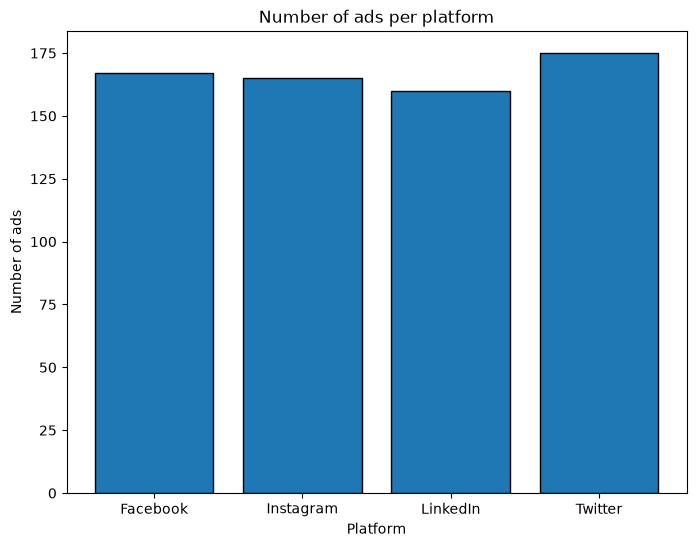

In [27]:
frequencies = data_cleaned['platform'].value_counts().sort_index()
proportion = data_cleaned['platform'].value_counts(normalize=True).sort_index()
print(frequencies)
print(proportion)

plt.figure(figsize=(8, 6))
plt.bar(frequencies.index, frequencies.values, edgecolor='black')
plt.title('Number of ads per platform')
plt.xlabel('Platform')
plt.ylabel('Number of ads')
plt.show()

## Question 1b Impressions per ad and its distribution
Mean and median, and a histogram with the normal distribution on top.

Average impressions per ad: 113925.0
Median impressions per ad: 111364.0
Standard deviation: 41895.41


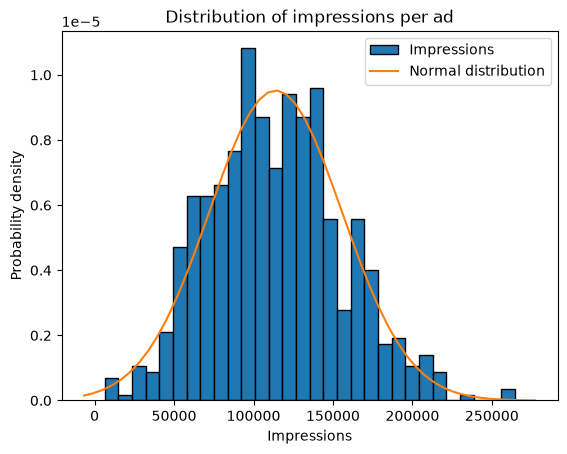

In [8]:
mu = np.mean(data_cleaned['impressions'])
sigma = np.std(data_cleaned['impressions'])
print('Average impressions per ad:', round(mu, 2))
print('Median impressions per ad:', np.median(data_cleaned['impressions']))
print('Standard deviation:', round(sigma, 2))

plt.hist(data_cleaned['impressions'], bins=30, density=True, edgecolor='black', label='Impressions')
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax)
plt.plot(x, stats.norm.pdf(x, mu, sigma), label='Normal distribution')
plt.title('Distribution of impressions per ad')
plt.xlabel('Impressions')
plt.ylabel('Probability density')
plt.legend()
plt.show()

## Question 1c Reach per platform

In [9]:
fb_reach = data_cleaned[data_cleaned['platform'] == 'Facebook']['reach']
ig_reach = data_cleaned[data_cleaned['platform'] == 'Instagram']['reach']
li_reach = data_cleaned[data_cleaned['platform'] == 'LinkedIn']['reach']
tw_reach = data_cleaned[data_cleaned['platform'] == 'Twitter']['reach']

print('All ads   - mean:', round(np.mean(data_cleaned['reach'])), ' median:', np.median(data_cleaned['reach']), ' std:', round(np.std(data_cleaned['reach'])))
print('Facebook  - mean:', round(np.mean(fb_reach)), ' median:', np.median(fb_reach), ' std:', round(np.std(fb_reach)))
print('Instagram - mean:', round(np.mean(ig_reach)), ' median:', np.median(ig_reach), ' std:', round(np.std(ig_reach)))
print('LinkedIn  - mean:', round(np.mean(li_reach)), ' median:', np.median(li_reach), ' std:', round(np.std(li_reach)))
print('Twitter   - mean:', round(np.mean(tw_reach)), ' median:', np.median(tw_reach), ' std:', round(np.std(tw_reach)))

All ads   - mean: 32836  median: 29883.0  std: 17536
Facebook  - mean: 37862  median: 36935.0  std: 14621
Instagram - mean: 47422  median: 44808.0  std: 19145
LinkedIn  - mean: 17400  median: 17364.5  std: 6835
Twitter   - mean: 28402  median: 28084.0  std: 10840


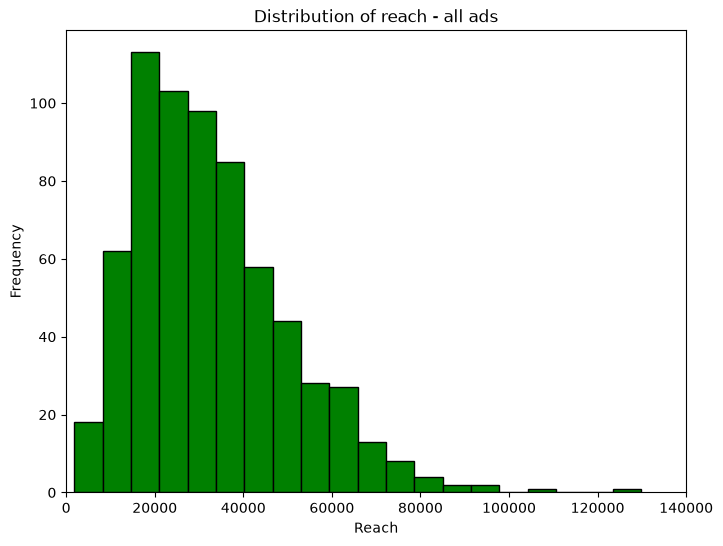

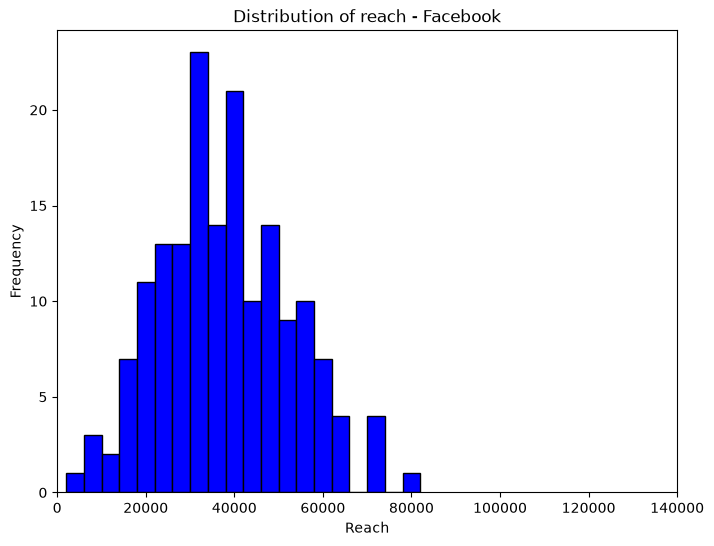

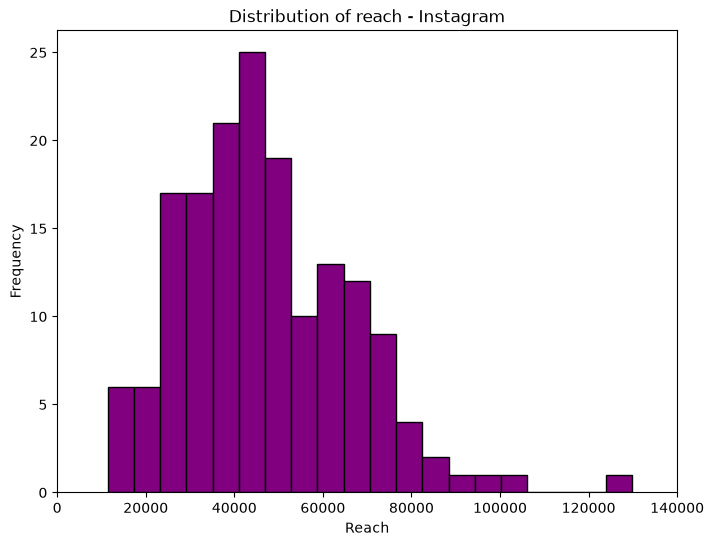

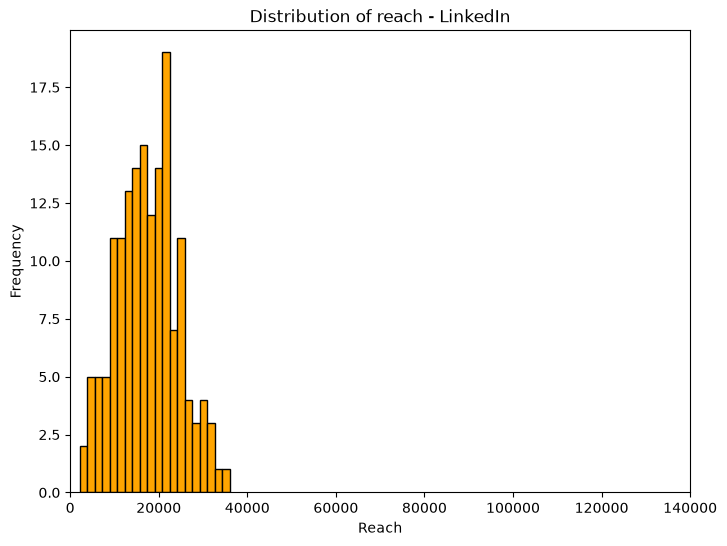

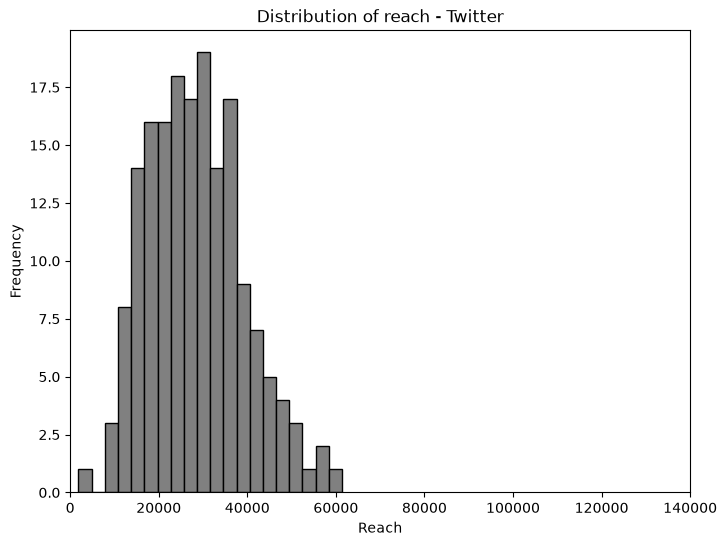

In [ ]:
plt.figure(figsize=(8, 6))
plt.hist(data_cleaned['reach'], bins=20, color='green', edgecolor='black')
plt.title('Distribution of reach - all ads')
plt.xlabel('Reach')
plt.ylabel('Frequency')
plt.xlim([0, 140000])
plt.show()

plt.figure(figsize=(8, 6))
plt.hist(fb_reach, bins=20, color='blue', edgecolor='black')
plt.title('Distribution of reach - Facebook')
plt.xlabel('Reach')
plt.ylabel('Frequency')
plt.xlim([0, 140000])
plt.show()

plt.figure(figsize=(8, 6))
plt.hist(ig_reach, bins=20, color='purple', edgecolor='black')
plt.title('Distribution of reach - Instagram')
plt.xlabel('Reach')
plt.ylabel('Frequency')
plt.xlim([0, 140000])
plt.show()

plt.figure(figsize=(8, 6))
plt.hist(li_reach, bins=20, color='orange', edgecolor='black')
plt.title('Distribution of reach - LinkedIn')
plt.xlabel('Reach')
plt.ylabel('Frequency')
plt.xlim([0, 140000])
plt.show()

plt.figure(figsize=(8, 6))
plt.hist(tw_reach, bins=20, color='grey', edgecolor='black')
plt.title('Distribution of reach - Twitter')
plt.xlabel('Reach')
plt.ylabel('Frequency')
plt.xlim([0, 140000])
plt.show()

## Question 2a Engagement rate

In [11]:
print('Average engagement rate (all ads):', round(np.mean(engagement_rate), 4))

fb_ads = data_cleaned[data_cleaned['platform'] == 'Facebook']
ig_ads = data_cleaned[data_cleaned['platform'] == 'Instagram']
li_ads = data_cleaned[data_cleaned['platform'] == 'LinkedIn']
tw_ads = data_cleaned[data_cleaned['platform'] == 'Twitter']

fb_er = fb_ads['engagements'] / fb_ads['impressions']
ig_er = ig_ads['engagements'] / ig_ads['impressions']
li_er = li_ads['engagements'] / li_ads['impressions']
tw_er = tw_ads['engagements'] / tw_ads['impressions']

print('Facebook:', round(np.mean(fb_er), 4))
print('Instagram:', round(np.mean(ig_er), 4))
print('LinkedIn:', round(np.mean(li_er), 4))
print('Twitter:', round(np.mean(tw_er), 4))

Average engagement rate (all ads): 0.0815
Facebook: 0.0765
Instagram: 0.1033
LinkedIn: 0.0674
Twitter: 0.0787


## Question 2b Model E(I) = a(1 − e^(−bI))
a = the highest engagement rate in the data, b = 0.000013.

a = 0.138


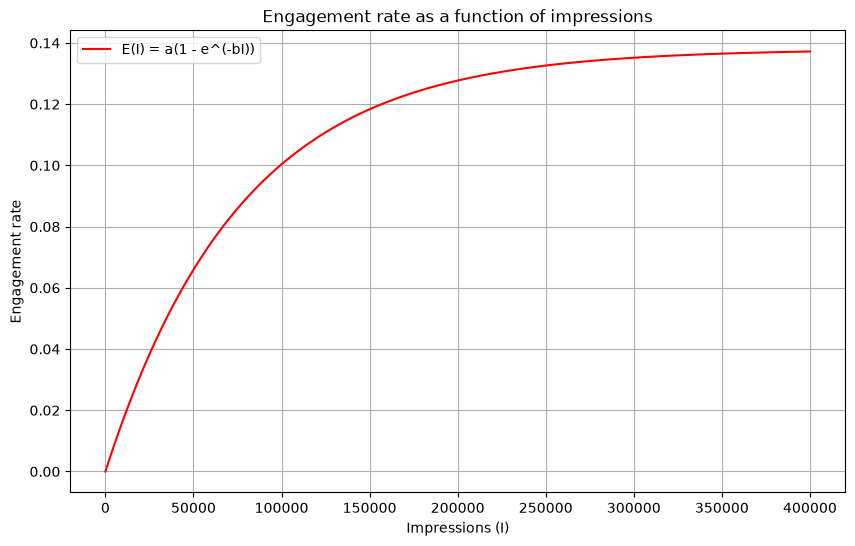

In [12]:
a = np.max(engagement_rate)
b = 0.000013
print('a =', round(a, 4))

def E(I):
    return a * (1 - np.exp(-b * I))

I_values = np.linspace(0, 400000, 500)
E_values = E(I_values)

plt.figure(figsize=(10, 6))
plt.plot(I_values, E_values, label='E(I) = a(1 - e^(-bI))', color='r')
plt.title('Engagement rate as a function of impressions')
plt.xlabel('Impressions (I)')
plt.ylabel('Engagement rate')
plt.legend()
plt.grid(True)
plt.show()

## Question 2c First derivative

In [13]:
I = symbols('I')
f = a * (1 - math.e**(-b * I))

dI_f = diff(f, I)
print('The derivative is:', dI_f)

print('Derivative at I = 0:', dI_f.subs(I, 0))
print('Derivative at I = 100000:', dI_f.subs(I, 100000))
print('Derivative at I = 200000:', dI_f.subs(I, 200000))

The derivative is: 1.79365459755145e-6/2.71828182845905**(1.3e-5*I)
Derivative at I = 0: 1.79365459755145e-6
Derivative at I = 100000: 4.88827903554396e-7
Derivative at I = 200000: 1.33221145040737e-7


## Question 3a Is the CTR of LinkedIn lower than the other platforms?
H0: CTR LinkedIn ≥ CTR other platforms. H1: CTR LinkedIn < CTR other platforms. α = 0.05.
One-way ANOVA with Tukey's HSD (more than 2 groups), then a one-sided t-test LinkedIn vs. the other platforms.

In [14]:
fb_ctr = data_cleaned[data_cleaned['platform'] == 'Facebook']['ctr']
ig_ctr = data_cleaned[data_cleaned['platform'] == 'Instagram']['ctr']
li_ctr = data_cleaned[data_cleaned['platform'] == 'LinkedIn']['ctr']
tw_ctr = data_cleaned[data_cleaned['platform'] == 'Twitter']['ctr']

print('Facebook:', round(np.mean(fb_ctr), 4))
print('Instagram:', round(np.mean(ig_ctr), 4))
print('LinkedIn:', round(np.mean(li_ctr), 4))
print('Twitter:', round(np.mean(tw_ctr), 4))

Facebook: 0.0603
Instagram: 0.075
LinkedIn: 0.025
Twitter: 0.0445


In [15]:
# One-way ANOVA
f_statistic, p_value = f_oneway(fb_ctr, ig_ctr, li_ctr, tw_ctr)
print(f"F-statistic: {f_statistic}")
print(f"P-value: {p_value}")

# Tukey's HSD post-hoc test
tukey_results = pairwise_tukeyhsd(endog=data_cleaned['ctr'], groups=data_cleaned['platform'], alpha=0.05)
print(tukey_results)

F-statistic: 3235.5317548903345
P-value: 0.0
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1    group2  meandiff p-adj  lower   upper  reject
---------------------------------------------------------
 Facebook Instagram   0.0147   0.0  0.0133  0.0161   True
 Facebook  LinkedIn  -0.0353   0.0 -0.0367 -0.0339   True
 Facebook   Twitter  -0.0158   0.0 -0.0171 -0.0144   True
Instagram  LinkedIn    -0.05   0.0 -0.0514 -0.0486   True
Instagram   Twitter  -0.0305   0.0 -0.0318 -0.0291   True
 LinkedIn   Twitter   0.0195   0.0  0.0181  0.0209   True
---------------------------------------------------------


In [16]:
# One-sided t-test: LinkedIn vs. the other platforms
other_platforms = ['Facebook', 'Instagram', 'Twitter']
other_ctr = data_cleaned[data_cleaned['platform'].isin(other_platforms)]['ctr']
print('Other platforms:', round(np.mean(other_ctr), 4))

ttest_result = ttest_ind(li_ctr, other_ctr, alternative='less')
print(ttest_result)

Other platforms: 0.0596
TtestResult(statistic=np.float64(-32.05728501199264), pvalue=np.float64(2.427862245614175e-137), df=np.float64(665.0))


## Question 3b Is the CVR of LinkedIn higher than Twitter?
H0: CVR LinkedIn ≤ CVR Twitter. H1: CVR LinkedIn > CVR Twitter. α = 0.05. One-sided t-test for unpaired groups.

In [17]:
li_cvr = data_cleaned[data_cleaned['platform'] == 'LinkedIn']['cvr']
tw_cvr = data_cleaned[data_cleaned['platform'] == 'Twitter']['cvr']

print('LinkedIn:', round(np.mean(li_cvr), 4))
print('Twitter:', round(np.mean(tw_cvr), 4))

ttest_result = ttest_ind(li_cvr, tw_cvr, alternative='greater')
print(ttest_result)

LinkedIn: 0.0899
Twitter: 0.03
TtestResult(statistic=np.float64(268.61320856672245), pvalue=np.float64(0.0), df=np.float64(333.0))


## Question 3c 95% confidence interval of the mean CVR
The text mentions Facebook ads, the question says all ads, so both are computed.

In [18]:
# Facebook ads
fb_cvr = data_cleaned[data_cleaned['platform'] == 'Facebook']['cvr']
n = len(fb_cvr)
mean = np.mean(fb_cvr)
std_err = sem(fb_cvr)
confidence_interval = t.interval(confidence=0.95, df=n-1, loc=mean, scale=std_err)
print('Facebook - mean:', round(mean, 4), ' confidence interval:', confidence_interval)

# All ads
n = len(data_cleaned)
mean = np.mean(data_cleaned['cvr'])
std_err = sem(data_cleaned['cvr'])
confidence_interval = t.interval(confidence=0.95, df=n-1, loc=mean, scale=std_err)
print('All ads - mean:', round(mean, 4), ' confidence interval:', confidence_interval)

Facebook - mean: 0.0701  confidence interval: (np.float64(0.06976308544937825), np.float64(0.07035549527774894))
All ads - mean: 0.0643  confidence interval: (np.float64(0.06262382696084515), np.float64(0.06597872834827948))


## Question 3d CVR of the 10% best Facebook ads (μ = 0.0812, σ = 0.001)

In [19]:
z = norm.ppf(0.90)
x = 0.0812 + z * 0.001
print('z =', round(z, 4))
print('The 10% best ads have a CVR of at least:', round(x, 5))

z = 1.2816
The 10% best ads have a CVR of at least: 0.08248


## Question 4a Probability of an engagement rate above 11%

In [20]:
n_ads = len(data_cleaned)
n_success = (engagement_rate > 0.11).sum()
print('Successful ads:', n_success, 'of', n_ads)
print('Probability:', round(n_success / n_ads, 4))

Successful ads: 69 of 667
Probability: 0.1034


## Question 4b Instagram vs. Facebook

In [21]:
ig_success = (ig_er > 0.11).sum()
fb_success = (fb_er > 0.11).sum()

print('Instagram:', ig_success, 'of', len(ig_er), '=', round(ig_success / len(ig_er), 4))
print('Facebook:', fb_success, 'of', len(fb_er), '=', round(fb_success / len(fb_er), 4))

Instagram: 68 of 165 = 0.4121
Facebook: 1 of 167 = 0.006


## Question 4c Bayesian update (2 of 50 ads successful this year)
Prior: α = successes last year, β = failures last year. Posterior: α + 2 and β + 48.

In [22]:
alpha_prior = n_success
beta_prior = n_ads - n_success
print('Prior mean:', round(alpha_prior / (alpha_prior + beta_prior), 4))

alpha_post = alpha_prior + 2
beta_post = beta_prior + 48
print('Posterior: alpha =', alpha_post, ' beta =', beta_post)
print('Posterior mean:', round(alpha_post / (alpha_post + beta_post), 4))

Prior mean: 0.1034
Posterior: alpha = 71  beta = 646
Posterior mean: 0.099


## Question 4d Probability that the probability of success is more than 11%

In [23]:
print('P(p > 0.11) =', round(1 - beta.cdf(x=0.11, a=alpha_post, b=beta_post), 4))

P(p > 0.11) = 0.1619


## Question 5a When does ad fatigue start?
Ad fatigue starts at the maximum of the function, where the derivative is 0.

In [24]:
day = symbols('day')
f = -50.64*day**2 + 1215.36*day

dday_f = diff(f)
print('The derivative of the function is:', dday_f)

days_maximum = solve(dday_f, day)
print('The derivative is zero at day:', days_maximum)

impressions_maximum = [f.subs(day, points) for points in days_maximum]
print('New impressions on that day:', impressions_maximum)

The derivative of the function is: 1215.36 - 101.28*day
The derivative is zero at day: [12.0000000000000]
New impressions on that day: [7292.16000000000]


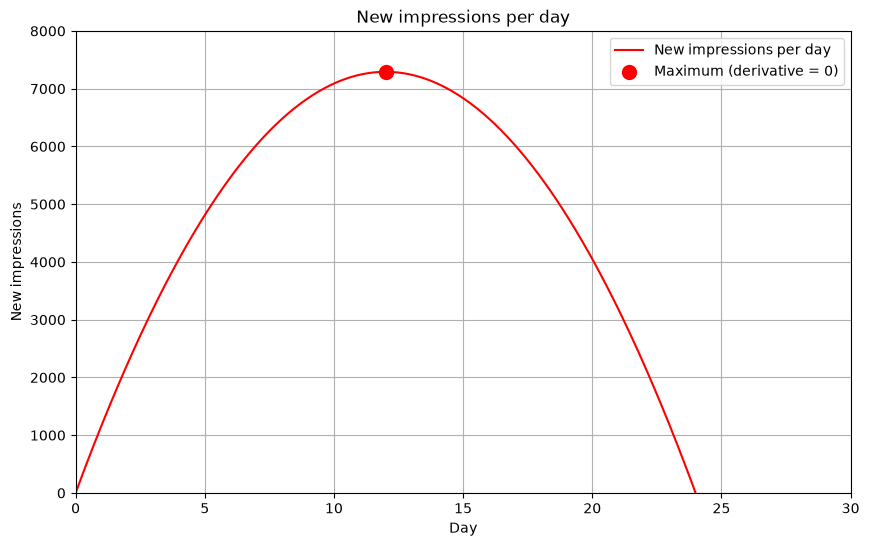

In [25]:
def new_impressions(t_day):
    return -50.64*t_day**2 + 1215.36*t_day

t_values = np.linspace(0, 30, 500)

plt.figure(figsize=(10, 6))
plt.plot(t_values, new_impressions(t_values), label='New impressions per day', color='r')
plt.scatter(12, 7292.16, color='red', s=100, label="Maximum (derivative = 0)")
plt.title('New impressions per day')
plt.xlabel('Day')
plt.ylabel('New impressions')
plt.xlim([0, 30])
plt.ylim([0, 8000])
plt.legend()
plt.grid(True)
plt.show()

## Question 5b Total impressions until day 12 (integral)

In [26]:
total_impressions, error = quad(new_impressions, 0, 12)
print(f'Total impressions from day 0 to 12: {total_impressions:.2f}')

Total impressions from day 0 to 12: 58337.28
